# Phase 7 — Rendre ton modèle rapide et léger

Entraîner un modèle, c'est une fois. Le faire **tourner** (l'inférence), c'est des millions de fois : c'est là que se jouent les coûts en production. Deux techniques, écrites à la main sur **ton** modèle :

1. **Le KV-cache** : pour ne plus recalculer tout le texte à chaque nouveau token → plus **rapide** ;
2. **La quantification** : stocker les poids sur 8 ou 4 bits au lieu de 32 → plus **léger**.

Et pour chacune, la question qui compte : **qu'est-ce qu'on perd en qualité ?**

**Kaggle :** GPU T4 recommandé pour les mesures de vitesse (le notebook marche aussi sur CPU, en plus lent). Internet On. Ton token Hugging Face est demandé si ton modèle instruct est encore privé.

In [18]:
!pip -q install tokenizers safetensors huggingface_hub
import os, sys, json, math, time, random, copy
from getpass import getpass
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download, login
from safetensors.torch import load_model
from tokenizers import Tokenizer

login(token=getpass("Token Hugging Face (Write) : "))

TRAVAIL = "/kaggle/working"
INSTRUCT = "Ezeck01/petit-gpt-fr-46m-instruct"
for f in ["model.py", "config.json", "tokenizer.json", "model.safetensors"]:
    hf_hub_download(INSTRUCT, f, local_dir=f"{TRAVAIL}/instruct")
sys.path.append(f"{TRAVAIL}/instruct")
from model import Config, GPT

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil :", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

modele = GPT(Config(**json.load(open(f"{TRAVAIL}/instruct/config.json"))))
load_model(modele, f"{TRAVAIL}/instruct/model.safetensors")
modele.to(device).eval()
config = modele.config
tokenizer = Tokenizer.from_file(f"{TRAVAIL}/instruct/tokenizer.json")
ID_UTIL, ID_ASSIST, ID_FIN = (tokenizer.token_to_id(t) for t in ("<|utilisateur|>", "<|assistant|>", "<|endoftext|>"))

def encoder(demande, reponse=None):
    ids = [ID_UTIL] + tokenizer.encode("\n" + demande + "\n").ids + [ID_ASSIST] + tokenizer.encode("\n").ids
    if reponse is None:
        return ids
    ids_reponse = tokenizer.encode(reponse).ids + [ID_FIN]
    return ids + ids_reponse, [-100] * len(ids) + ids_reponse

def synchro():
    if device == "cuda":
        torch.cuda.synchronize()     # le GPU travaille en différé : on attend qu'il ait fini avant de chronométrer
print("Ton modèle instruct est chargé.")

Token Hugging Face (Write) :  ········


model.py:   0%|          | 0.00/4.04k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.15M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  186MB            

model.safetensors: downloading bytes:           |  0.00B            

Appareil : Tesla T4
Ton modèle instruct est chargé.


## 1. Le problème : la génération naïve

Jusqu'ici, pour générer un token, on redonnait **tout le texte** au modèle : la question + tous les tokens déjà générés. Au token 300, on recalcule les 299 précédents… alors qu'on les avait déjà calculés au token 299.

Le travail par token **grandit avec la longueur** du texte. Mesurons-le : on génère 400 tokens et on chronomètre chaque token.

In [19]:
@torch.no_grad()
def generer_naif(ids, n):
    x = torch.tensor([ids], device=device)
    temps = []
    for _ in range(n):
        synchro(); t0 = time.perf_counter()
        logits, _ = modele(x)                        # TOUT le texte, à chaque fois
        suivant = logits[0, -1].argmax().view(1, 1)
        synchro(); temps.append(time.perf_counter() - t0)
        x = torch.cat([x, suivant], dim=1)
    return x[0].tolist(), temps

depart = encoder("Raconte l'histoire d'un village au bord d'un fleuve.")
N_TOKENS = config.block_size - len(depart) - 1       # on remplit tout le contexte disponible
generer_naif(depart, 5)                              # échauffement (le premier appel est toujours lent)
sortie_naive, temps_naif = generer_naif(depart, N_TOKENS)
print(f"{N_TOKENS} tokens générés en {sum(temps_naif):.2f} s -> {N_TOKENS / sum(temps_naif):.0f} tokens/s")
print(f"Temps par token : {temps_naif[0] * 1000:.1f} ms au début, {np.mean(temps_naif[-20:]) * 1000:.1f} ms à la fin")

489 tokens générés en 4.82 s -> 101 tokens/s
Temps par token : 6.2 ms au début, 15.5 ms à la fin


## 2. Le KV-cache

Rappel de l'attention (phase 3) : chaque token produit une requête **q**, une clé **k** et une valeur **v**. Pour prédire le token suivant, la requête du **dernier** token est comparée aux clés de **tous** les tokens précédents.

L'observation clé : **les k et v des anciens tokens ne changent jamais**. Le masque causal garantit qu'un token ne voit que le passé, donc ajouter un nouveau token à la fin ne modifie rien de ce qui précède.

D'où l'idée : on **garde en mémoire** (cache) les k et v de chaque bloc. À chaque nouveau token :
1. on calcule q, k, v **pour ce seul token** ;
2. on ajoute son k et son v au cache ;
3. sa requête regarde toutes les clés du cache.

On écrit nous-mêmes le passage dans le modèle, en réutilisant **ses** couches (`qkv`, `proj`, `mlp`…) : les poids sont exactement les mêmes.

In [20]:
@torch.no_grad()
def avancer(m, ids, cache):
    """Fait passer `ids` (les NOUVEAUX tokens) dans le modèle, en utilisant et en complétant le cache."""
    debut = 0 if cache[0] is None else cache[0][0].shape[2]          # combien de tokens sont déjà en cache
    T = ids.shape[1]
    x = m.emb_tokens(ids) + m.emb_position(torch.arange(debut, debut + T, device=ids.device))
    for i, bloc in enumerate(m.blocs):
        a = bloc.attn
        h = bloc.ln1(x)
        B, _, C = h.shape
        q, k, v = a.qkv(h).split(C, dim=2)
        q, k, v = (t.view(B, T, a.n_head, C // a.n_head).transpose(1, 2) for t in (q, k, v))
        if cache[i] is not None:                                     # on ajoute aux k, v déjà calculés
            k = torch.cat([cache[i][0], k], dim=2)
            v = torch.cat([cache[i][1], v], dim=2)
        cache[i] = (k, v)
        # Plusieurs nouveaux tokens d'un coup (la question) : masque causal.
        # Un seul nouveau token : il a le droit de tout voir, pas de masque.
        y = F.scaled_dot_product_attention(q, k, v, is_causal=(T > 1))
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        x = x + a.proj(y)
        x = x + bloc.mlp(bloc.ln2(x))
    return m.tete(m.ln_final(x))

@torch.no_grad()
def generer_cache(ids, n, m=None):
    m = m or modele
    cache = [None] * len(m.blocs)
    logits = avancer(m, torch.tensor([ids], device=device), cache)   # la question, en une fois ("prefill")
    sortie, temps = list(ids), []
    for _ in range(n):
        synchro(); t0 = time.perf_counter()
        suivant = logits[0, -1].argmax()
        sortie.append(suivant.item())
        logits = avancer(m, suivant.view(1, 1), cache)               # UN seul token à la fois
        synchro(); temps.append(time.perf_counter() - t0)
    return sortie, temps

### Vérification : est-ce le même calcul ?

Une optimisation qui change le résultat est un **bug**, pas une optimisation. On vérifie deux choses :
- les **logits** (les scores du modèle) sont identiques, à l'arrondi près ;
- le texte généré (décodage glouton) est le **même token pour token**.

In [21]:
with torch.no_grad():
    texte = torch.tensor([sortie_naive[:200]], device=device)
    logits_naif, _ = modele(texte)
    cache = [None] * len(modele.blocs)
    logits_cache = torch.cat([avancer(modele, texte[:, :50], cache)] +
                             [avancer(modele, texte[:, t:t + 1], cache) for t in range(50, 200)], dim=1)
ecart = (logits_naif - logits_cache).abs().max().item()
print(f"Écart maximal entre les logits : {ecart:.2e}  (les deux calculs diffèrent seulement par l'arrondi)")

generer_cache(depart, 5)                                            # échauffement
sortie_cache, temps_cache = generer_cache(depart, N_TOKENS)
identiques = sum(a == b for a, b in zip(sortie_naive, sortie_cache))
print(f"Tokens identiques : {identiques} / {len(sortie_naive)}")

Écart maximal entre les logits : 3.14e-05  (les deux calculs diffèrent seulement par l'arrondi)
Tokens identiques : 511 / 511


Si quelques tokens diffèrent vers la fin, ce n'est pas une erreur : deux calculs mathématiquement égaux, faits dans un ordre différent, donnent des arrondis très légèrement différents. Quand deux tokens ont presque le même score, l'arrondi peut faire basculer le choix, et à partir de là les deux textes divergent. L'écart sur les logits, lui, doit rester minuscule.

### La vitesse

Naïf     :    101 tokens/s
KV-cache :    176 tokens/s  -> x1.7


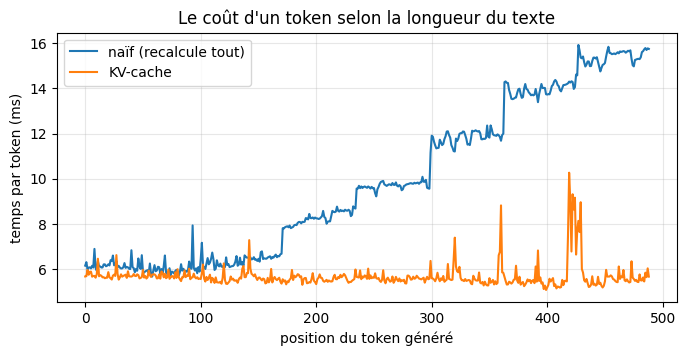

In [22]:
print(f"Naïf     : {N_TOKENS / sum(temps_naif):>6.0f} tokens/s")
print(f"KV-cache : {N_TOKENS / sum(temps_cache):>6.0f} tokens/s  -> x{sum(temps_naif) / sum(temps_cache):.1f}")

plt.figure(figsize=(8, 3.5))
plt.plot(np.array(temps_naif) * 1000, label="naïf (recalcule tout)")
plt.plot(np.array(temps_cache) * 1000, label="KV-cache")
plt.xlabel("position du token généré"); plt.ylabel("temps par token (ms)")
plt.title("Le coût d'un token selon la longueur du texte"); plt.legend(); plt.grid(alpha=.3)
plt.show()

Lis la courbe : en naïf, le temps par token **monte** avec la longueur (on refait de plus en plus de travail). Avec le cache, il reste **à peu près plat** : chaque token ne coûte que son propre calcul, plus la lecture du cache.

**Le prix à payer : la mémoire.** Le cache stocke k et v pour chaque token, dans chaque bloc. Pour les grands modèles et les longs contextes, c'est souvent le cache, et pas les poids, qui remplit la mémoire du GPU.

In [23]:
octets = 2 * config.n_layer * config.block_size * config.n_embd * 4          # k et v, 12 blocs, 512 tokens, float32
print(f"Taille du KV-cache plein ({config.block_size} tokens) : {octets / 1e6:.1f} Mo")
print(f"Taille des poids du modèle : {sum(p.numel() for p in modele.parameters()) * 4 / 1e6:.0f} Mo")
print("\nPour comparaison, un modèle de 70 milliards de paramètres avec 100 000 tokens de contexte :")
print("le cache se compte en dizaines de Go.")

Taille du KV-cache plein (512 tokens) : 25.2 Mo
Taille des poids du modèle : 186 Mo

Pour comparaison, un modèle de 70 milliards de paramètres avec 100 000 tokens de contexte :
le cache se compte en dizaines de Go.


## 3. La quantification

Chaque poids est stocké en **float32** : 4 octets. L'idée : le remplacer par un petit entier.

Pour une ligne de poids, on cherche la plus grande valeur absolue, on en déduit une **échelle**, puis on arrondit chaque poids au cran le plus proche :
- **8 bits** : 255 crans (de −127 à +127) ;
- **4 bits** : seulement 15 crans (de −7 à +7).

```
échelle = max(|w|) / 127
w_entier = arrondi(w / échelle)        <- ce qu'on stocke (1 octet)
w ≈ w_entier × échelle                 <- ce qu'on reconstitue au moment du calcul
```

Moins de crans = plus léger, mais plus d'erreur d'arrondi. Regarde sur quelques vrais poids de ton modèle :

In [24]:
def quantifier(w, bits, groupe=None):
    """Arrondit w sur `bits` bits. Une échelle par ligne, ou par paquet de `groupe` poids."""
    qmax = 2 ** (bits - 1) - 1
    forme = w.shape
    if groupe:
        w = w.reshape(forme[0], -1, groupe)
    echelle = w.abs().amax(dim=-1, keepdim=True).clamp(min=1e-8) / qmax
    w_q = (w / echelle).round().clamp(-qmax, qmax)
    return (w_q * echelle).reshape(forme)          # on reconstitue pour mesurer l'effet

w = modele.blocs[0].mlp.fc.weight.detach()[0, :8].float()
print("Poids originaux :", [f"{x:+.4f}" for x in w.tolist()])
for b in [8, 4]:
    print(f"Sur {b} bits     :", [f"{x:+.4f}" for x in quantifier(w[None], b)[0].tolist()])

Poids originaux : ['-0.0222', '-0.0103', '+0.0313', '+0.0102', '-0.0437', '+0.0422', '-0.0143', '-0.0393']
Sur 8 bits     : ['-0.0224', '-0.0103', '+0.0313', '+0.0103', '-0.0437', '+0.0423', '-0.0141', '-0.0392']
Sur 4 bits     : ['-0.0250', '-0.0125', '+0.0312', '+0.0125', '-0.0437', '+0.0437', '-0.0125', '-0.0375']


### Quel effet sur la qualité ?

On quantifie **toutes les matrices** du modèle (attention, MLP, embeddings) et on mesure la perte sur des réponses du jeu de SFT. On va jusqu'à 2 bits pour voir où ça casse.

On teste aussi la **quantification par groupes** : au lieu d'une seule échelle pour toute une ligne (512 ou 2048 poids), une échelle pour chaque paquet de 64 poids. Si une ligne contient une seule valeur très grande, elle n'écrase plus la précision de toute la ligne. C'est ce que font les vraies méthodes (les formats Q4 de llama.cpp, GPTQ, AWQ).

⚠️ Ces exemples ont pu être vus pendant le SFT : la perte absolue est optimiste. Ce qui compte ici, c'est la **comparaison** entre niveaux de quantification, sur les mêmes exemples.

In [25]:
chemin = hf_hub_download("jpacifico/French-Alpaca-dataset-Instruct-110K",
                         "Acquiesce_data_110k_instructions.json", repo_type="dataset", local_dir=TRAVAIL)
donnees = json.load(open(chemin, encoding="utf-8"))
random.seed(42)
test = []
for ex in random.sample(donnees, 600):
    demande = (ex["instruction"] + (("\n\n" + ex["input"]) if ex["input"] else "")).strip()
    ids, cibles = encoder(demande, ex["output"].strip())
    if ex["output"].strip() and len(ids) <= config.block_size:
        test.append((ids, cibles))
test = test[:300]

@torch.no_grad()
def perte(m):
    total, n = 0.0, 0
    for k in range(0, len(test), 16):
        lot = test[k:k + 16]
        L = max(len(i) for i, _ in lot)
        x = torch.full((len(lot), L), ID_FIN, dtype=torch.long)
        y = torch.full((len(lot), L), -100, dtype=torch.long)
        for j, (ids, cib) in enumerate(lot):
            x[j, :len(ids)] = torch.tensor(ids); y[j, :len(cib) - 1] = torch.tensor(cib[1:])
        _, p = m(x.to(device), y.to(device))
        nb = (y != -100).sum().item()
        total += p.item() * nb; n += nb
    return total / n

def version_quantifiee(bits, groupe=None):
    m = copy.deepcopy(modele)
    with torch.no_grad():
        for mod in m.modules():
            if isinstance(mod, (nn.Linear, nn.Embedding)) and mod.weight.dim() == 2:
                if mod is m.tete:
                    continue                 # partage ses poids avec emb_tokens : déjà quantifiée
                if bits == 16:
                    mod.weight.copy_(mod.weight.half().float())
                else:
                    mod.weight.copy_(quantifier(mod.weight, bits, groupe))
    return m

n_poids = sum(mod.weight.numel() for mod in modele.modules()
              if isinstance(mod, (nn.Linear, nn.Embedding)) and mod is not modele.tete)
reste = sum(p.numel() for p in modele.parameters()) - n_poids
def memoire(bits, groupe=None):
    echelles = (n_poids / groupe if groupe else sum(mod.weight.shape[0] for mod in modele.modules()
                if isinstance(mod, (nn.Linear, nn.Embedding)) and mod is not modele.tete)) * 2
    return (n_poids * bits / 8 + echelles + reste * 2) / 1e6 if bits < 32 else (n_poids + reste) * 4 / 1e6

resultats = []
for nom, bits, groupe in [("float32 (original)", 32, None), ("float16", 16, None),
                          ("8 bits", 8, None), ("6 bits", 6, None),
                          ("4 bits", 4, None), ("4 bits, groupes de 64", 4, 64),
                          ("3 bits, groupes de 64", 3, 64), ("2 bits, groupes de 64", 2, 64)]:
    m = modele if bits == 32 else version_quantifiee(bits, groupe)
    p = perte(m)
    resultats.append((nom, bits, groupe, memoire(bits, groupe), p))
    if m is not modele:
        del m
p0 = resultats[0][4]
print(f"{'Format':<24}{'Mémoire':>10}{'Perte':>9}{'Écart':>9}")
print("-" * 52)
for nom, bits, groupe, mo, p in resultats:
    print(f"{nom:<24}{mo:>8.0f} Mo{p:>9.3f}{p - p0:>+9.3f}")

Format                     Mémoire    Perte    Écart
----------------------------------------------------
float32 (original)           186 Mo    1.435   +0.000
float16                       93 Mo    1.435   -0.000
8 bits                        47 Mo    1.435   +0.000
6 bits                        35 Mo    1.441   +0.006
4 bits                        23 Mo    1.574   +0.140
4 bits, groupes de 64         25 Mo    1.496   +0.062
3 bits, groupes de 64         19 Mo    1.829   +0.394
2 bits, groupes de 64         13 Mo    8.329   +6.894


Lis la colonne **Écart** : jusqu'à un certain nombre de bits, la perte ne bouge presque pas. Le modèle est **tolérant** au bruit d'arrondi. Puis, en dessous d'un seuil, elle s'effondre. Compare aussi les deux lignes « 4 bits » : l'effet des groupes.

**Une précision honnête :** ici, on *simule* la quantification (on arrondit les poids puis on calcule en float32). La mémoire indiquée est celle qu'on obtiendrait en stockant vraiment les entiers. Pour gagner aussi en **vitesse**, il faut des programmes spécialisés qui calculent directement avec les entiers (bitsandbytes, llama.cpp…). Le principe et l'effet sur la qualité, eux, sont exactement ceux-là.

### À l'œil : les réponses selon la quantification

In [26]:
questions = ["Pourquoi le ciel est-il bleu ?", "Qu'est-ce que la photosynthèse ?", "Donne trois conseils pour bien dormir."]
for nom, bits, groupe in [("float32", 32, None), ("8 bits", 8, None), ("4 bits, groupes de 64", 4, 64),
                          ("3 bits, groupes de 64", 3, 64), ("2 bits, groupes de 64", 2, 64)]:
    m = modele if bits == 32 else version_quantifiee(bits, groupe)
    print(f"=== {nom} ===")
    for q in questions:
        ids, _ = generer_cache(encoder(q), 60, m)
        rep = tokenizer.decode(ids[len(encoder(q)):]).split("<|endoftext|>")[0]
        print("  ", rep.strip().replace("\n", " / ")[:160])
    print()

=== float32 ===
   Le ciel est bleu à cause de la diffusion de la lumière du soleil par les molécules d'air.Le ciel est bleu à cause de la diffusion de la lumière du soleil par le
   La photosynthèse est le processus par lequel les plantes, les algues et certaines bactéries convertissent la lumière du soleil en énergie chimique.La photosynth
   Pour bien dormir, il est important de se fixer des objectifs réalistes, de se fixer des objectifs réalistes, et de se fixer des objectifs réalistes.La gestion d

=== 8 bits ===
   Le ciel est bleu à cause de la diffusion de la lumière du soleil par les molécules d'air.Le ciel est bleu à cause de la diffusion de la lumière du soleil par le
   La photosynthèse est le processus par lequel les plantes, les algues et certaines bactéries convertissent la lumière du soleil en énergie chimique.La photosynth
   Pour bien dormir, il est important de se fixer des objectifs réalistes, de se fixer des objectifs réalistes, et de se fixer des objectifs réalist

## 4. Le bilan

Remplis-le avec tes chiffres : c'est le tableau à mettre dans ta fiche et sur ton CV.

| Technique | Gain | Coût |
|---|---|---|
| KV-cache | × ? en vitesse | ? Mo de mémoire en plus |
| 8 bits | ÷ ? en mémoire | ? de perte |
| 4 bits par groupes | ÷ ? en mémoire | ? de perte |

**Pour aller plus loin** (si tu veux une phase 7-bis) : le **speculative decoding**. Un tout petit modèle « brouillon » propose plusieurs tokens d'un coup, et ton modèle les vérifie tous en un seul passage. Quand le brouillon a raison, on gagne plusieurs tokens pour le prix d'un.